# 05 · Q2 — Rute mana yang tetap untung setelah ongkos angkut?

**Keputusan yang didukung:** rute pemindahan stok yang layak (dari kota sumber ke kota tujuan).

**Metode** (`src/analysis/spread.py`, `config.analisis.q2_rute`, `config/biaya_logistik.yaml`):
- **Harga beli** = harga **pedagang besar** di kota sumber (lebih realistis untuk distributor daripada harga eceran);
  nilai nyata terakhir tiap minggu (pedagang besar dicatat ±Kamis). Minggu dengan harga sumber usang dikecualikan.
- **Harga jual** = harga **pasar tradisional** di kota tujuan (sesuai brief).
- **Ongkos angkut = perkiraan, bukan data**: (tarif truk/km × jarak jalan + tol) / muatan + bongkar-muat + susut.
- Untung per kg = selisih harga − ongkos angkut. Diuji dengan ongkos ×0,5 / ×1 / ×1,5 / ×2.
- **Rute layak** hanya jika pada ongkos ×1,5: untung pada ≥ 60% minggu **dan** median untung > 0 (brief).

In [1]:
import re
import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..")
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis.common import load_cfg  # noqa: E402
cfg, lcfg = load_cfg()


def tampilkan_temuan(laporan: str) -> None:
    """Ambil bagian 'Temuan (bahasa dashboard)' dari laporan yang baru dibuat skrip, lalu tampilkan apa adanya."""
    teks = (ROOT / "reports" / laporan).read_text(encoding="utf-8")
    m = re.search(r"## Temuan \(bahasa dashboard\)\n(.*?)\n## ", teks, re.S)
    display(Markdown(m.group(1).strip() if m else "(bagian temuan tidak ditemukan)"))


def gambar(path) -> None:
    display(Image(filename=str(path)))

from src.analysis import spread as S
res = S.run(cfg, lcfg)
print(f"{res['ringkas'][['kota_sumber_id','kota_tujuan_id','komoditas_id']].drop_duplicates().shape[0]} rute x komoditas diuji")

32 rute x komoditas diuji


## 1. Komponen ongkos angkut per rute (perkiraan)
Detail sumber setiap angka: `docs/biaya_logistik_report.md`.

In [2]:
b = pd.read_csv(ROOT / "data" / "reference" / "biaya_rute.csv")
b[["kota_sumber", "kota_tujuan", "kualitas", "jarak_jalan_km", "ongkos_angkut_rp_per_kg", "susut_rp_per_kg",
   "biaya_logistik_x1_rp_per_kg", "status_mpp"]].round(0).head(12)

,kota_sumber,kota_tujuan,kualitas,jarak_jalan_km,ongkos_angkut_rp_per_kg,susut_rp_per_kg,biaya_logistik_x1_rp_per_kg,status_mpp
0,Kota Tasikmalaya,Kota Jakarta Pusat,Cabai Merah Keriting,262.000,835.000,"2,000.000","2,835.000",ok
1,Kota Tasikmalaya,Kota Bandung,Cabai Merah Keriting,108.000,434.000,"2,000.000","2,434.000",ok
2,Kota Tasikmalaya,Kota Semarang,Cabai Merah Keriting,327.000,"1,006.000","2,000.000","3,006.000",ok
3,Kota Tasikmalaya,Kota Surabaya,Cabai Merah Keriting,621.000,"1,775.000","2,000.000","3,775.000",ok
4,Kota Tegal,Kota Jakarta Pusat,Bawang Merah Ukuran Sedang,286.000,649.000,"1,035.000","1,684.000",ok
5,Kota Tegal,Kota Bandung,Bawang Merah Ukuran Sedang,203.000,504.000,"1,035.000","1,539.000",ok
6,Kota Tegal,Kota Semarang,Bawang Merah Ukuran Sedang,154.000,419.000,"1,035.000","1,454.000",ok
7,Kota Tegal,Kota Surabaya,Bawang Merah Ukuran Sedang,463.000,958.000,"1,035.000","1,993.000",ok
8,Kota Kediri,Kota Jakarta Pusat,Cabai Rawit Merah,688.000,"1,951.000","2,612.000","4,563.000",ok
9,Kota Kediri,Kota Bandung,Cabai Rawit Merah,606.000,"1,735.000","2,612.000","4,347.000",ok


## 2. Uji sensitivitas: kalau ongkos ternyata 0,5× … 2×

In [3]:
res["sens"]

,pengali,rute_untung_median_positif,rute_untung_60pct_minggu
0,0.500,30,29
1,1.000,28,28
2,1.500,27,23
3,2.000,22,22


## 3. Semua rute pada skenario konservatif (ongkos ×1,5)

In [4]:
k = res["ringkas"][res["ringkas"].pengali == res["kons"]].sort_values("median_untung_rp_per_kg", ascending=False)
k[["kualitas", "kota_sumber", "kota_tujuan", "selisih_kotor_median_rp_per_kg", "biaya_logistik_median_rp_per_kg",
   "median_untung_rp_per_kg", "porsi_minggu_untung", "persistensi_rata_minggu", "untung_dari_jendela",
   "layak_konservatif"]].round(2)

,kualitas,kota_sumber,kota_tujuan,selisih_kotor_median_rp_per_kg,biaya_logistik_median_rp_per_kg,median_untung_rp_per_kg,porsi_minggu_untung,persistensi_rata_minggu,untung_dari_jendela,layak_konservatif
38,Cabai Rawit Merah,Kota Kediri,Kota Bandung,"26,450.000","5,414.310","21,048.190",0.970,41.500,10,True
86,Cabai Rawit Merah,Kab. Jember,Kota Bandung,"27,200.000","6,434.910","20,852.590",0.960,27.330,10,True
34,Cabai Rawit Merah,Kota Kediri,Kota Jakarta Pusat,"26,000.000","5,738.550","20,173.950",1.000,171.000,10,True
82,Cabai Rawit Merah,Kab. Jember,Kota Jakarta Pusat,"26,150.000","6,759.540","19,377.960",0.990,85.000,10,True
6,Cabai Merah Keriting,Kota Tasikmalaya,Kota Bandung,"20,500.000","3,538.000","17,099.500",0.980,42.000,9,True
102,Cabai Rawit Merah,Kab. Banyuwangi,Kota Bandung,"22,750.000","6,888.940","15,411.060",0.920,14.270,10,True
98,Cabai Rawit Merah,Kab. Banyuwangi,Kota Jakarta Pusat,"22,575.000","7,213.170","14,886.830",0.980,42.000,10,True
18,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Jakarta Pusat,"15,000.000","2,324.220","12,790.780",1.000,171.000,10,True
114,Bawang Merah Ukuran Sedang,Kota Probolinggo,Kota Jakarta Pusat,"16,000.000","3,706.230","12,443.770",1.000,171.000,10,True
22,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Bandung,"13,750.000","2,105.450","11,664.560",1.000,171.000,10,True


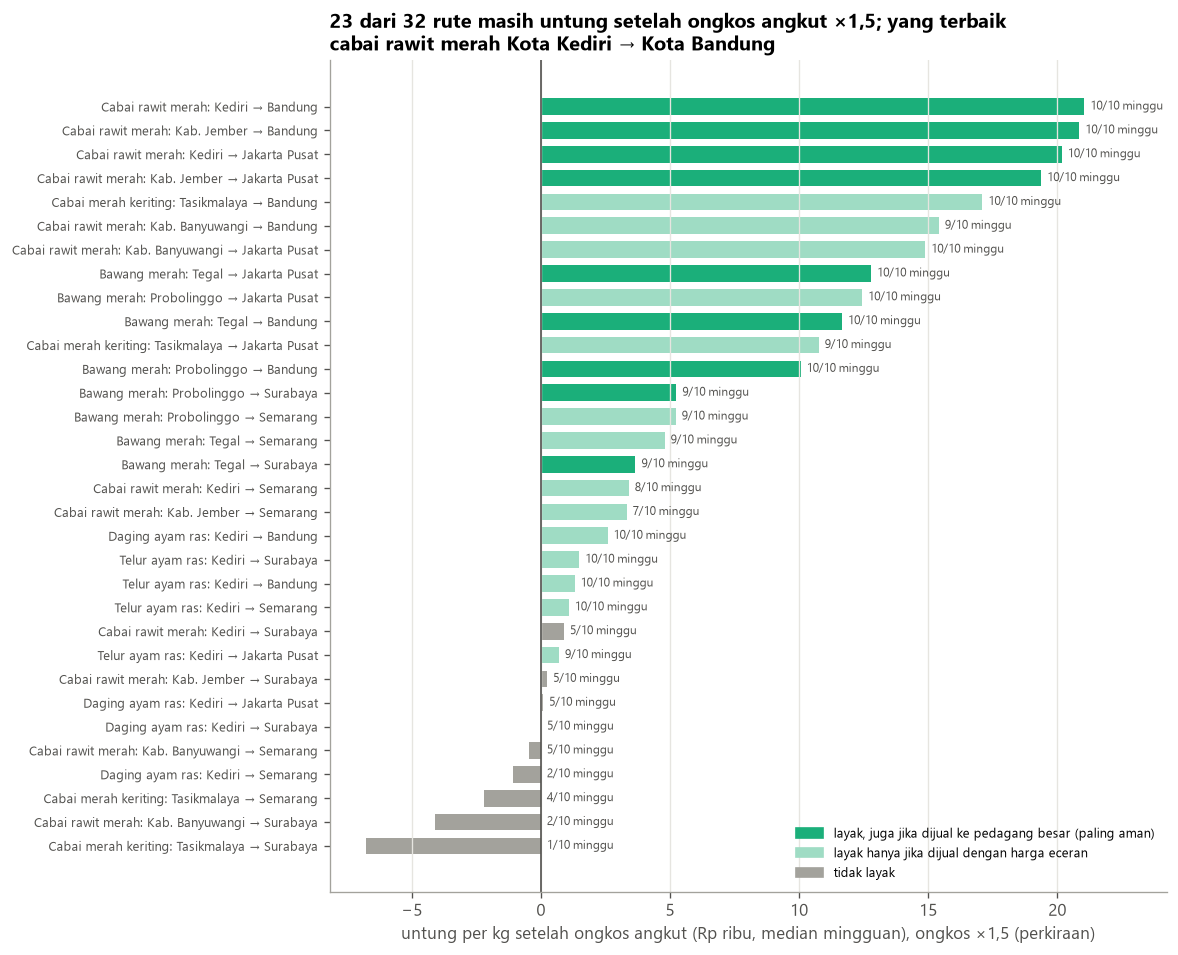

In [5]:
figs = S.figures(res)
gambar(figs["rute"])

## 4. Uji ketahanan: bagaimana kalau dijual ke pedagang besar di kota tujuan?
Harga eceran memuat margin pengecer. Distributor biasanya menjual ke pedagang, bukan langsung ke konsumen, jadi
analisis diulang dengan harga **pedagang besar** di kota tujuan sebagai harga jual. Rute yang layak di **kedua** cara
hitung adalah rekomendasi yang paling aman.

In [6]:
aman = k[k.layak_konservatif & k.layak_jika_jual_ke_pedagang_besar]
print(f"Layak (jual eceran): {int(k.layak_konservatif.sum())} | layak jika jual ke pedagang besar: "
      f"{int(k.layak_jika_jual_ke_pedagang_besar.sum())} | layak di kedua cara: {len(aman)}")
aman[["kualitas", "kota_sumber", "kota_tujuan", "median_untung_rp_per_kg", "median_untung_jual_ke_pedagang_besar",
      "porsi_untung_jual_ke_pedagang_besar"]].round(2)

Layak (jual eceran): 23 | layak jika jual ke pedagang besar: 9 | layak di kedua cara: 9


,kualitas,kota_sumber,kota_tujuan,median_untung_rp_per_kg,median_untung_jual_ke_pedagang_besar,porsi_untung_jual_ke_pedagang_besar
38,Cabai Rawit Merah,Kota Kediri,Kota Bandung,"21,048.190","3,460.690",0.640
86,Cabai Rawit Merah,Kab. Jember,Kota Bandung,"20,852.590","2,427.590",0.650
34,Cabai Rawit Merah,Kota Kediri,Kota Jakarta Pusat,"20,173.950","6,948.950",0.700
82,Cabai Rawit Merah,Kab. Jember,Kota Jakarta Pusat,"19,377.960","6,652.960",0.670
18,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Jakarta Pusat,"12,790.780","2,675.780",0.680
22,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Bandung,"11,664.560","2,669.560",0.750
118,Bawang Merah Ukuran Sedang,Kota Probolinggo,Kota Bandung,"10,061.170","1,419.920",0.630
126,Bawang Merah Ukuran Sedang,Kota Probolinggo,Kota Surabaya,"5,245.320","2,972.820",0.750
30,Bawang Merah Ukuran Sedang,Kota Tegal,Kota Surabaya,"3,662.580","1,577.580",0.730


## 5. Rute terbaik: selisih harga vs garis ongkos angkut

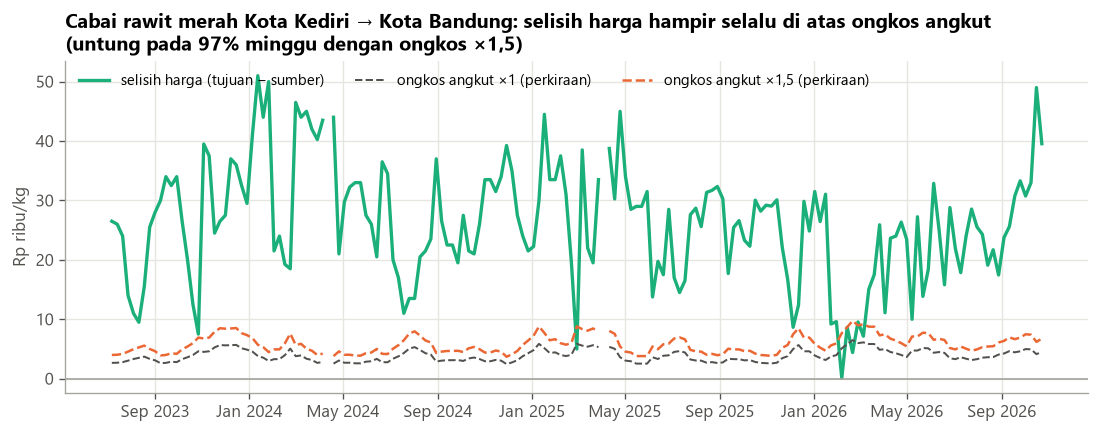

In [7]:
gambar(figs["terbaik"])

### Catatan metode: persistensi
"Peluang biasanya bertahan x minggu" = rata-rata panjang rangkaian minggu untung berturut-turut. Minggu tanpa data
(mis. minggu Lebaran tanpa pencatatan) **dilewati**, tidak dianggap memutus rangkaian; versi awal yang memutus rangkaian
menghasilkan angka "57 minggu" yang menyesatkan (`docs/audit_analisis.md`).

### Temuan (bahasa dashboard)
Kalimat di bawah **tidak diketik tangan**: diambil dari laporan yang baru saja dibuat skrip, sehingga selalu sama dengan
angka di tabel di atas.

In [8]:
S.write_summary(res, figs, cfg)
tampilkan_temuan("q2_rute.md")

**23 rute masih untung setelah ongkos angkut; yang terbaik cabai rawit merah Kota Kediri → Kota Bandung.**
(Dari 32 rute yang diuji, dengan ongkos angkut ×1,5 perkiraan.) Di rute terbaik, harga di Kota Bandung rata-rata
Rp 26.450/kg lebih mahal daripada harga pedagang besar di Kota Kediri; setelah ongkos angkut
masih tersisa sekitar Rp 21.048/kg. Minggu untung: 9,7 dari 10.
Tindakan: prioritaskan rute yang layak; untuk rute lain, pindahkan stok hanya saat selisih minggu itu jauh di atas ongkos.

**Uji ketahanan:** jika stok dijual ke pedagang besar di kota tujuan (bukan dengan harga eceran), rute yang layak tinggal
**9 dari 32**. 9 rute layak di kedua cara hitung; inilah rekomendasi yang paling aman.
Uji paling berat (ongkos ×2 **dan** dijual ke pedagang besar): **6 dari 9** rute itu tetap layak.
Yang tidak lagi untung minimal 6 dari 10 minggu: cabai rawit merah Kota Kediri ke Kota Bandung (5,8 dari 10 minggu); cabai rawit merah Kab. Jember ke Kota Bandung (5,3 dari 10 minggu); bawang merah Kota Probolinggo ke Kota Bandung (5,5 dari 10 minggu).